# Plot Dispersion Curves

Multi-event visualization of Rayleigh **dispersion curves** from the combined BRS pipeline. This notebook:

- Loads `./results/dispersion_curves.yaml` produced by **04_brs_combine_results.py** after per-event analysis
- Builds per-event DataFrames for **velocity** and **acceleration** dispersion (frequencies vs. phase velocity)
- Aligns curves on a common frequency grid and computes cohort **median** and **percentiles**
- Plots all individual curves, statistical summaries, and combined velocity vs. acceleration comparisons
- Saves figures under `./results/` (e.g. `dispersion_curves_velocity.png`)

Run **04_brs_combine_results.py** first. Optional: rename duplicate-date events (e.g. `event_20230206_01` → `event_20230206a`) and set `EXCLUDE_EVENT_DATES` after merge to drop events from `df_vel` plots and statistics.

## Imports

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml


def check_pandas_working():
    try:
        pd.DataFrame({"velocity": [1.0]}, index=[0.01])
    except TypeError as exc:
        if "Cannot convert numpy.ndarray" in str(exc):
            raise RuntimeError(
                "pandas/numpy are incompatible in this kernel. Run:\n"
                "  conda activate sixdegrees\n"
                "  conda install 'pandas>=1.5,<2.2' 'numpy>=1.24,<2' --force-reinstall\n"
                "Then restart the kernel and re-run Imports."
            ) from exc
        raise


def dispersion_to_dataframe(frequencies, velocities, value_col="velocity"):
    check_pandas_working()
    f = np.asarray(frequencies, dtype=float).ravel()
    v = np.asarray(velocities, dtype=float).ravel()
    if f.size != v.size:
        n = min(f.size, v.size)
        f, v = f[:n], v[:n]
    valid = np.isfinite(f) & (f > 0) & np.isfinite(v) & (v > 0)
    f, v = f[valid], v[valid]
    if f.size == 0:
        return None
    seen = {}
    for freq, vel in sorted(zip(f.tolist(), v.tolist()), key=lambda x: x[0]):
        if freq not in seen:
            seen[float(freq)] = float(vel)
    index = list(seen.keys())
    df = pd.DataFrame({value_col: [seen[k] for k in index]}, index=index)
    df.index.name = "frequency"
    return df


def merge_dispersion_tables(df_dict, target_frequencies):
    check_pandas_working()
    target = np.unique(np.sort(np.asarray(target_frequencies, dtype=float)))
    merged = pd.DataFrame(index=target)
    merged.index.name = "frequency"
    for event_name, df_event in df_dict.items():
        merged[event_name] = df_event.iloc[:, 0].reindex(target)
    return merged


check_pandas_working()

## Load Dispersion Data

In [76]:
# Load dispersion curves YAML file
with open('./output/dispersion_curves.yaml', 'r') as f:
    dispersion_data = yaml.load(f, Loader=yaml.FullLoader)

print(f"Loaded {len(dispersion_data)} events")
print(f"\nEvents: {list(dispersion_data.keys())}")

Loaded 18 events

Events: ['event_20190706', 'event_20200623', 'event_20200722', 'event_20201019', 'event_20210304', 'event_20230206_01', 'event_20230206_02', 'event_20230908', 'event_20240402', 'event_20240628', 'event_20240915', 'event_20241205', 'event_20241217', 'event_20250208', 'event_20250328', 'event_20250716', 'event_20250729', 'event_20251208']


## Convert Each Event to DataFrame

Convert each event's dispersion data into a DataFrame with frequencies as rows.

In [77]:
# Convert each event to a DataFrame with frequencies as rows
df_vel_dict = {}
df_acc_dict = {}

for event_name, event_data in dispersion_data.items():
    if event_data.get('velocity'):
        vel_data = event_data['velocity']
        df_temp = dispersion_to_dataframe(
            vel_data['frequencies'],
            vel_data['velocities'],
            value_col='velocity',
        )
        if df_temp is not None:
            df_vel_dict[event_name] = df_temp

    if event_data.get('acceleration'):
        acc_data = event_data['acceleration']
        df_temp = dispersion_to_dataframe(
            acc_data['frequencies'],
            acc_data['velocities'],
            value_col='velocity',
        )
        if df_temp is not None:
            df_acc_dict[event_name] = df_temp

print(f"Converted {len(df_vel_dict)} velocity DataFrames")
print(f"Converted {len(df_acc_dict)} acceleration DataFrames")

Converted 18 velocity DataFrames
Converted 0 acceleration DataFrames


## Find Event with Most Frequencies and Merge DataFrames

In [78]:
# Find event with most frequencies for velocity
if len(df_vel_dict) > 0:
    vel_lengths = {event: len(df.index) for event, df in df_vel_dict.items()}
    vel_longest_event = max(vel_lengths, key=vel_lengths.get)
    vel_longest_frequencies = df_vel_dict[vel_longest_event].index.values
    
    # Ensure frequencies are unique and sorted
    vel_longest_frequencies = np.unique(vel_longest_frequencies)
    vel_longest_frequencies = np.sort(vel_longest_frequencies)
    
    print(f"Velocity: Event with most frequencies: {vel_longest_event} ({len(vel_longest_frequencies)} frequencies)")
    print(f"  Frequency range: {vel_longest_frequencies[0]:.4f} - {vel_longest_frequencies[-1]:.4f} Hz")
    
    df_vel = merge_dispersion_tables(df_vel_dict, vel_longest_frequencies)
    print(f"Merged velocity DataFrame: {len(df_vel)} frequency points, {len(df_vel.columns)} events")
else:
    df_vel = None
    vel_longest_frequencies = None

# Find event with most frequencies for acceleration
if len(df_acc_dict) > 0:
    acc_lengths = {event: len(df.index) for event, df in df_acc_dict.items()}
    acc_longest_event = max(acc_lengths, key=acc_lengths.get)
    acc_longest_frequencies = df_acc_dict[acc_longest_event].index.values
    
    # Ensure frequencies are unique and sorted
    acc_longest_frequencies = np.unique(acc_longest_frequencies)
    acc_longest_frequencies = np.sort(acc_longest_frequencies)
    
    print(f"\nAcceleration: Event with most frequencies: {acc_longest_event} ({len(acc_longest_frequencies)} frequencies)")
    print(f"  Frequency range: {acc_longest_frequencies[0]:.4f} - {acc_longest_frequencies[-1]:.4f} Hz")
    
    df_acc = merge_dispersion_tables(df_acc_dict, acc_longest_frequencies)
    print(f"Merged acceleration DataFrame: {len(df_acc)} frequency points, {len(df_acc.columns)} events")
else:
    df_acc = None
    acc_longest_frequencies = None

Velocity: Event with most frequencies: event_20190706 (8 frequencies)
  Frequency range: 0.0188 - 0.2113 Hz
Merged velocity DataFrame: 8 frequency points, 18 events


In [79]:
EXCLUDE_EVENT_DATES = [
    "20200623",
    "20241217",
    # "20230206",  # drops both 20230206a and 20230206b
]

In [80]:
import re

df_vel.rename(columns={"event_20230206_01": "event_20230206a"}, inplace=True)
df_vel.rename(columns={"event_20230206_02": "event_20230206b"}, inplace=True)


def _event_date_from_column(col):
    m = re.match(r"event_(\d{8})", str(col))
    return m.group(1) if m else None


def drop_events_by_date(df, exclude_dates):
    if df is None or not exclude_dates:
        return df
    exclude = {str(d).replace("-", "")[:8] for d in exclude_dates}
    drop_cols = [c for c in df.columns if _event_date_from_column(c) in exclude]
    if not drop_cols:
        return df
    print(f"Dropped {len(drop_cols)} velocity event(s): {drop_cols}")
    return df.drop(columns=drop_cols)


df_vel = drop_events_by_date(df_vel, EXCLUDE_EVENT_DATES)
if df_vel is not None and len(df_vel.columns) == 0:
    df_vel = None
    print("No velocity events left after date exclusion")
elif df_vel is not None:
    print(f"Velocity table: {len(df_vel.columns)} event(s) — {list(df_vel.columns)}")

Dropped 2 velocity event(s): ['event_20200623', 'event_20241217']
Velocity table: 16 event(s) — ['event_20190706', 'event_20200722', 'event_20201019', 'event_20210304', 'event_20230206a', 'event_20230206b', 'event_20230908', 'event_20240402', 'event_20240628', 'event_20240915', 'event_20241205', 'event_20250208', 'event_20250328', 'event_20250716', 'event_20250729', 'event_20251208']


## Compute Statistics

Calculate median and percentiles for each frequency.

In [81]:
# Compute statistics for velocity
if df_vel is not None and len(df_vel.columns) > 0:
    median_vel = df_vel.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    freq_array_vel = df_vel.index.values
    
    print(f"Velocity Statistics:")
    print(f"  Number of events: {len(df_vel.columns)}")
    print(f"  Number of frequency points: {len(freq_array_vel)}")
    print(f"  Median velocity range: {np.nanmin(median_vel.values):.1f} - {np.nanmax(median_vel.values):.1f} m/s")
else:
    median_vel = None
    p20_vel = None
    p80_vel = None
    freq_array_vel = None

# Compute statistics for acceleration
if df_acc is not None and len(df_acc.columns) > 0:
    median_acc = df_acc.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_acc = df_acc.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_acc = df_acc.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    freq_array_acc = df_acc.index.values
    
    print(f"\nAcceleration Statistics:")
    print(f"  Number of events: {len(df_acc.columns)}")
    print(f"  Number of frequency points: {len(freq_array_acc)}")
    print(f"  Median velocity range: {np.nanmin(median_acc.values):.1f} - {np.nanmax(median_acc.values):.1f} m/s")
else:
    median_acc = None
    p20_acc = None
    p80_acc = None
    freq_array_acc = None

Velocity Statistics:
  Number of events: 16
  Number of frequency points: 8
  Median velocity range: 1800.0 - 3050.0 m/s


In [82]:
# Velocity - Median and percentiles
if df_vel is not None and len(df_vel.columns) > 0:
    
    # Calculate statistics at each frequency point using nanmedian and nanpercentile
    median_vel = df_vel.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    
    # Get frequencies
    freq_array = df_vel.index.values
    

## Plot All Individual Dispersion Curves

Plot all individual curves color-coded by event.

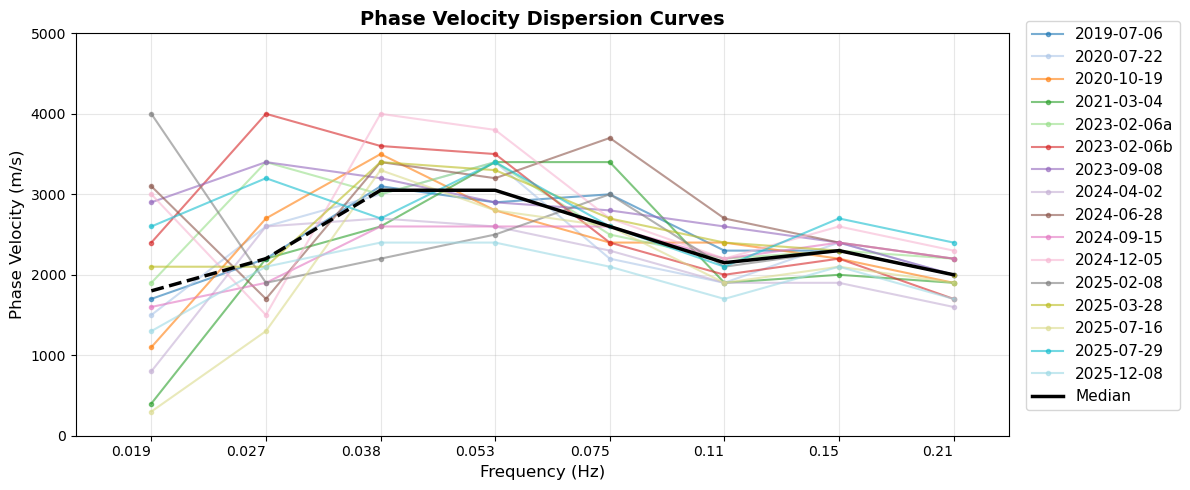

In [83]:
# Velocity curves
if df_vel is not None and len(df_vel.columns) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))
    
    # Get unique events and assign colors
    events = df_vel.columns.tolist()
    colors = plt.cm.tab20(np.linspace(0, 1, len(events)))
    event_colors = dict(zip(events, colors))
    
    for event_name in events:
        # make event label 
        event_label = event_name.replace('event_', '')
        # change format for label: insert - after 4 and after 6
        event_label = event_label[:4] + '-' + event_label[4:6] + '-' + event_label[6:]

        ax.plot(df_vel.index, df_vel[event_name], 
               color=event_colors[event_name], 
               alpha=0.6, linewidth=1.5, label=event_label, marker='o', markersize=3)

    # Plot median
    ax.plot(freq_array[:3], median_vel.values[:3], 'k--', linewidth=2.5, zorder=5)
    ax.plot(freq_array[2:], median_vel.values[2:], 'k-', linewidth=2.5, label='Median', zorder=5)

    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title('Phase Velocity Dispersion Curves', fontsize=14, fontweight='bold')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(bbox_to_anchor=(1.01, 1.05), loc='upper left', fontsize=11, ncol=1)
    ax.set_ylim(0, 5000)
    ax.set_xlim(0.015, 0.25)

    # Major ticks only at analysis frequencies (no log-scale minor ticks)
    from matplotlib.ticker import NullLocator

    freq_ticks = df_vel.index[(df_vel.index >= 0.015) & (df_vel.index <= 0.25)]
    ax.set_xticks(freq_ticks)
    ax.set_xticklabels(
        [f"{f:.3f}" if f < 0.1 else f"{f:.2f}" for f in freq_ticks],
        rotation=0,
        ha='right',
    )
    ax.xaxis.set_minor_locator(NullLocator())
    ax.tick_params(axis='x', which='major', labelsize=10)
    ax.tick_params(axis='x', which='minor', length=0)

    plt.tight_layout()
    plt.show()
    
    fig.savefig("./figures/dispersion_curves_velocity.png", bbox_inches='tight', dpi=200)

else:
    print("No velocity curves to plot")


In [55]:
# Acceleration curves
if df_acc is not None and len(df_acc.columns) > 0:
    fig, ax = plt.subplots(figsize=(12, 5))
    
    # Get unique events and assign colors
    events = df_acc.columns.tolist()
    colors = plt.cm.tab20(np.linspace(0, 1, len(events)))
    event_colors = dict(zip(events, colors))
    
    for event_name in events:
        ax.plot(df_acc.index, df_acc[event_name], 
               color=event_colors[event_name], 
               alpha=0.6, linewidth=1.5, label=event_name.replace('event_', ''), marker='o', markersize=3)

    # Plot median
    ax.plot(freq_array[2:], median_vel.values[2:], 'k-', linewidth=2.5, label='Median', zorder=5)
    
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title('All Acceleration Dispersion Curves', fontsize=14, fontweight='bold')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9, ncol=1)
    ax.set_ylim(0, 5000)
    ax.set_xlim(0.01, 0.3)

    plt.tight_layout()
    plt.show()

    fig.savefig("./results/dispersion_curves_acceleration.png", bbox_inches='tight', dpi=150)
    
else:
    print("No acceleration curves to plot")

No acceleration curves to plot


## Plot Median and Percentiles

Plot median dispersion curve with shaded percentile regions.

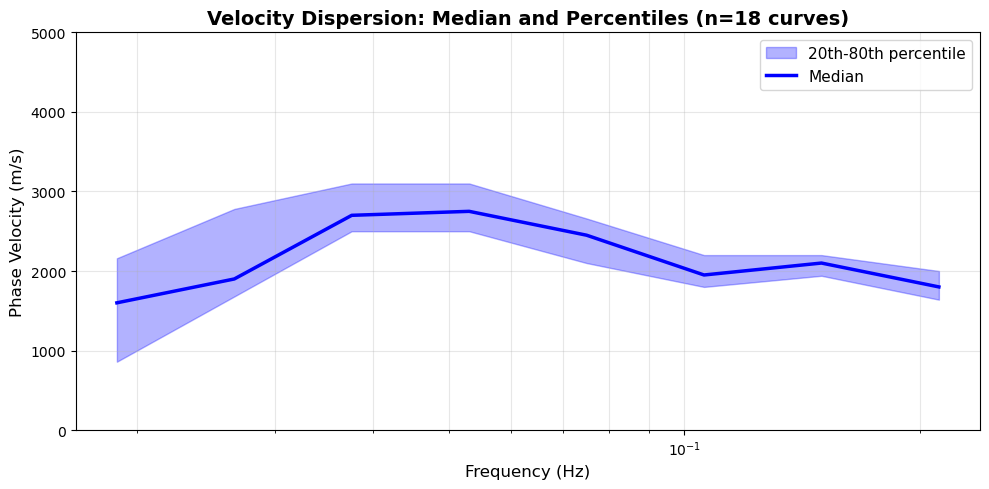


Velocity Statistics:
  Number of curves: 18
  Median velocity range: 1600.0 - 2750.0 m/s
  Frequency range: 0.0188 - 0.2113 Hz


In [56]:
# Velocity - Median and percentiles
if df_vel is not None and len(df_vel.columns) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Calculate statistics at each frequency point using nanmedian and nanpercentile
    median_vel = df_vel.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    
    # Get frequencies
    freq_array = df_vel.index.values
    
    # Plot percentile region
    ax.fill_between(freq_array, p20_vel, p80_vel, 
                    alpha=0.3, color='blue', label='20th-80th percentile')
    
    # Plot median
    ax.plot(freq_array, median_vel, 'b-', linewidth=2.5, label='Median', zorder=5)
    
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title(f'Velocity Dispersion: Median and Percentiles (n={len(df_vel.columns)} curves)', 
                 fontsize=14, fontweight='bold')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=11, loc='best')
    ax.set_ylim(0, 5000)

    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\nVelocity Statistics:")
    print(f"  Number of curves: {len(df_vel.columns)}")
    print(f"  Median velocity range: {np.nanmin(median_vel.values):.1f} - {np.nanmax(median_vel.values):.1f} m/s")
    print(f"  Frequency range: {freq_array[0]:.4f} - {freq_array[-1]:.4f} Hz")
else:
    print("No velocity curves available for statistics")

In [57]:
# Acceleration - Median and percentiles
if df_acc is not None and len(df_acc.columns) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Calculate statistics at each frequency point using nanmedian and nanpercentile
    median_acc = df_acc.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_acc = df_acc.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_acc = df_acc.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    
    # Get frequencies
    freq_array = df_acc.index.values
    
    # Plot percentile region
    ax.fill_between(freq_array, p20_acc, p80_acc, 
                    alpha=0.3, color='red', label='20th-80th percentile')
    
    # Plot median
    ax.plot(freq_array, median_acc, 'r-', linewidth=2.5, label='Median', zorder=5)
    
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title(f'Acceleration Dispersion: Median and Percentiles (n={len(df_acc.columns)} curves)', 
                 fontsize=14, fontweight='bold')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=11, loc='best')
    ax.set_ylim(0, 5000)

    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\nAcceleration Statistics:")
    print(f"  Number of curves: {len(df_acc.columns)}")
    print(f"  Median velocity range: {np.nanmin(median_acc.values):.1f} - {np.nanmax(median_acc.values):.1f} m/s")
    print(f"  Frequency range: {freq_array[0]:.4f} - {freq_array[-1]:.4f} Hz")
else:
    print("No acceleration curves available for statistics")

No acceleration curves available for statistics


## Combined Plot

Plot both velocity and acceleration statistics together for comparison.

In [58]:
# Combined velocity and acceleration
if (df_vel is not None and len(df_vel.columns) > 0 and 
    df_acc is not None and len(df_acc.columns) > 0):
    
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Velocity statistics using nanmedian and nanpercentile
    median_vel = df_vel.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_vel = df_vel.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    freq_array_vel = df_vel.index.values
    
    # Acceleration statistics using nanmedian and nanpercentile
    median_acc = df_acc.apply(lambda row: np.nanmedian(row.values), axis=1)
    p20_acc = df_acc.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    p80_acc = df_acc.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)
    freq_array_acc = df_acc.index.values
    
    # Plot velocity percentiles
    ax.fill_between(freq_array_vel, p20_vel, p80_vel, 
                    alpha=0.25, color='blue', label='Velocity: 20th-80th percentile')
    ax.plot(freq_array_vel, median_vel, 'b-', linewidth=2.5, label='Velocity: Median', zorder=5)
    
    # Plot acceleration percentiles
    ax.fill_between(freq_array_acc, p20_acc, p80_acc, 
                    alpha=0.25, color='red', label='Acceleration: 20th-80th percentile')
    ax.plot(freq_array_acc, median_acc, 'r-', linewidth=2.5, label='Acceleration: Median', zorder=5)
    
    ax.set_xlabel('Frequency (Hz)', fontsize=12)
    ax.set_ylabel('Phase Velocity (m/s)', fontsize=12)
    ax.set_title('Dispersion Curves: Velocity vs Acceleration Statistics', 
                 fontsize=14, fontweight='bold')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend(fontsize=10, loc='best', ncol=2)
    ax.set_ylim(0, 5000)

    plt.tight_layout()
    plt.show()
else:
    print("Cannot create combined plot - missing velocity or acceleration data")

Cannot create combined plot - missing velocity or acceleration data
